# ALGORITMO SCRATCH  DE WORD2VEC ( Retomado de  (Sudharsan Ravichandiran)[https://github.com/sudharsan13296/Word2vec-from-scratch/blob/master/word2vec%20scratch.ipynb])
Este es un  paso a paso o scratch del algoritmo de Word2vec, el cuál utiliza un modelo de regresión logística mutinomial o Softmax  como una red neuronal de tres capas (1 capa de entrada, 1 capa oculta y 1 capa de salida) produciendo la representación vectorial de las palabras más cercanas a cada palabra centro en un vocabulario dado que no es anotado a mano sino que el conjunto de entrenamiento se forma  de la co-ocurrencia con ventana fija y parametrizable de las palabras centros con sus palabras contextuales. En resumen, el algoritmo tiene tres partes (que se muestran en la gráfica)

1. Preprocesamiento de los conjuntos de entrenamiento y testeo y la   reducción matricial del vocabulario de entrada a la dimensión de embedding

2. Representación oculta de los vectores de entrada.

3. Onbtención de los vectores de contexto del venctor de entrada y representación vectorial de los vectores de entrada y los de contexto


In [ ]:
from IPython.display import Image
Image(filename='pilu2.png')

FileNotFoundError: ignored

In [ ]:
#import tensorflow as tf
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
import numpy as np # version 1.16

# setup a virtual environment
# pipenv shell
# pip install tensorflow numpy==1.16 sklearn matplotlib

2023-06-29 17:48:51.788198: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Instructions for updating:
non-resource variables are not supported in the long term


In [ ]:
corpus_raw1 = 'He is the king . The king is royal . She is the royal  queen '
corpus_raw = ' Me gusta jugar fútbol con mis amigos'
# convert to lower case
corpus_raw = corpus_raw.lower()

words = []
for word in corpus_raw.split():
    if word != '.': # because we don't want to treat . as a word
        words.append(word)

words = set(words) # so that all duplicate words are removed
word2int = {}
int2word = {}
vocab_size = len(words) # gives the total number of unique words
print(vocab_size)

7


In [ ]:

for i,word in enumerate(words):
    word2int[word] = i
    int2word[i] = word

# raw sentences is a list of sentences.
raw_sentences = corpus_raw.split('.')
sentences = []
for sentence in raw_sentences:
    sentences.append(sentence.split())
    print(sentences)
    #print(word2int['sentences.split()'])

[['me', 'gusta', 'jugar', 'fútbol', 'con', 'mis', 'amigos']]


#  En esta parte se obtienen todas las parejas de palabras que co-ocurren entre la palabra centro y las palabras de contexto dependiendo del tamaño de la ventana. Si el tamaño de la ventana  WINDOW_SIZE  es más grande  hay más posibilidad de encontrar más palabras cercanas  y el conjunto de entrenamiento crece.

In [ ]:
WINDOW_SIZE = 2

data = []
for sentence in sentences:
    for word_index, word in enumerate(sentence):
        for nb_word in sentence[max(word_index - WINDOW_SIZE, 0) : min(word_index + WINDOW_SIZE, len(sentence)) + 1] :
            if nb_word != word:
                data.append([word, nb_word])


# Aquí se forman todas las co-ocurrencias de ventana fija (WINDOW_SIZE=2) de cada palabra centro con las palabras de contexto, que son 2 a la izquierda y 2 a la derecha. En este caso cada palabra del vocabulario se convierte en una palabra centro y las que están alrededor las palabras contextuales.

In [ ]:
print(data)
print(len(data))

[['me', 'gusta'], ['me', 'jugar'], ['gusta', 'me'], ['gusta', 'jugar'], ['gusta', 'fútbol'], ['jugar', 'me'], ['jugar', 'gusta'], ['jugar', 'fútbol'], ['jugar', 'con'], ['fútbol', 'gusta'], ['fútbol', 'jugar'], ['fútbol', 'con'], ['fútbol', 'mis'], ['con', 'jugar'], ['con', 'fútbol'], ['con', 'mis'], ['con', 'amigos'], ['mis', 'fútbol'], ['mis', 'con'], ['mis', 'amigos'], ['amigos', 'con'], ['amigos', 'mis']]
22


# Las parejas de entrenamiento (x_train,y_train)  se forman de las  palabras centro con las palabras de contexto del vocabulario, en la tabla  los ejemplos de entrenamiento  de (I,like) y (I,playing) tienen las siguientes representaciones  ([1,0,0,0,0,0,0],[0,1,0,0,0,0,0]) y ([1,0,0,0,0,0,0],[0,0,1,0,0,0,0])

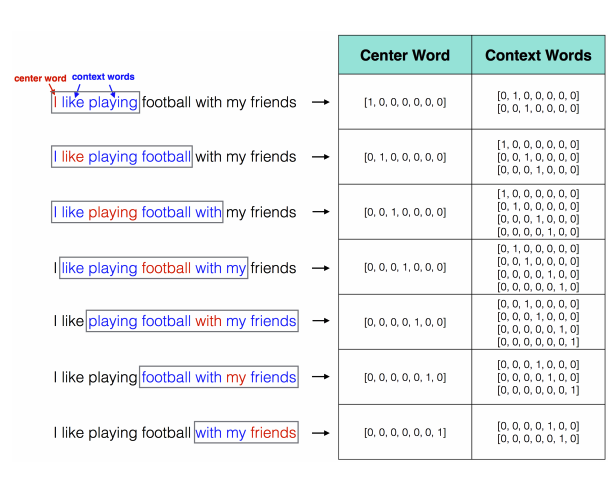

In [ ]:
from IPython.display import Image
Image(filename='x-train.png')

# Esta es la función one-hot que asigna 1 en la posición de la palabra dependiendo de su ubicación en el vector que tiene como dimensión el tamaño del vocabulario.

In [ ]:
# function to convert numbers to one hot vectors
def to_one_hot(data_point_index, vocab_size):
    temp = np.zeros(vocab_size)
    temp[data_point_index] = 1
    return temp

# Las x_train y y_train son las mismas palabras del vocabulario que son organizadas dependiendo del tamaño del vocabulario y la ventena de acercamiento, para este ejemplo, el tamaño de la ventana es de 2 con tamaño de vocabulario de 7, por lo tanto tendríamos  22 ejemplos  representados en one-hot.  En términos generales, x_train y y_train son dos matrices de (22,7), por cada vector de x_train de 7 elementos hay un vector y_train de 7 elementos.

In [ ]:
x_train = [] # input word
y_train = [] # output word

for data_word in data:
    x_train.append(to_one_hot(word2int[ data_word[0] ], vocab_size))
    y_train.append(to_one_hot(word2int[ data_word[1] ], vocab_size))
    #print(data_word[0],data_word[1])
    #print(x_train,y_train)
x_train = np.asarray(x_train)
y_train = np.asarray(y_train)

#print(x_train,'parejas',y_train,'\n')
    #print(data_word[0],y_train)
# convert them to numpy arrays


print('conjunto X de entrenamiento---------')
print(x_train,y_train,'\n')
#print(x_train.shape)
#print('conjunto Y de entrenamiento---------')
#print(y_train)
#print(y_train.shape)

conjunto X de entrenamiento---------
[[0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0.]] [[0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [

In [ ]:
print(x_train.shape[0])
#puntos de entrenamiento, donde cada punto tiene 7 dimensiones, que crecen depeniendo de la ventana de contexto

22


# En esta parte se obtiene la reducción del tamaño del vocabulario a un embedding más pequeño y más denso usando una distribución probabilística Gaussiana (librería de numpy) tanto para W1 y para b1. Reservado el espacio de (x_train,y_train) se obtiene una capa de representación oculta multiplicando W1.x +b1 (este es el modelo de perceptron básico).  Se puede observar que las dimensiones de la matriz W1 tiene en las filas el tamaño del vocubulario que viene de la entrada de las palabras  y en las columnas la dimensión del embedding ajustable y parametrizable, el b1 tiene la dimensión del embedding.
![pilu1.png](attachment:pilu1.png)


In [ ]:
# Se reserva el espacio para x_train y y_train
x = tf.placeholder(tf.float32, shape=(None, vocab_size))
y_label = tf.placeholder(tf.float32, shape=(None, vocab_size))

EMBEDDING_DIM = 10 # you can choose your own number
W1 = tf.Variable(tf.random_normal([vocab_size, EMBEDDING_DIM]))
b1 = tf.Variable(tf.random_normal([EMBEDDING_DIM])) #bias
hidden_representation = tf.add(tf.matmul(x,W1), b1)
print(hidden_representation.shape)
print(b1)

(?, 10)
<tf.Variable 'Variable_1:0' shape=(10,) dtype=float32_ref>


 # La matriz W2 tiene como  dimensiones el embedding_dim que es un parámetro ajustable y se sugiere que sea de 300 y el tamaño del vocabulario  para que sea compatible con la salida de los vectores de contexto. En esta parte se usa la función  de regresión multinomial  Softmax para volver estos valores reales en probabildades, la entrada de los x ya viene con sus pesos dimensionada  de manera lineal  x.W1 +b1 pero que a su vez W1 se ajusta de acuerdo a la optimización de  la función de perdida sobre los datos de entrenamiento. Finalmente, la Softmax es la predicción del modelo que son las palabras  más cercanas a la palabra de entrada y la vectorización de las palabras del vocabulario se determinan por la matriz W1.  



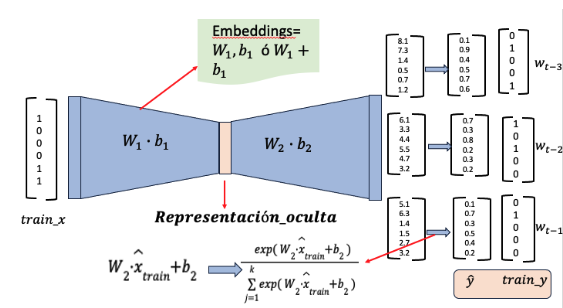

In [ ]:
from IPython.display import Image
Image(filename='pilu.png')

In [ ]:
W2 = tf.Variable(tf.random_normal([EMBEDDING_DIM, vocab_size]))
b2 = tf.Variable(tf.random_normal([vocab_size]))
prediction = tf.nn.softmax(tf.add( tf.matmul(hidden_representation, W2), b2))
print(prediction)

Tensor("Softmax:0", shape=(?, 7), dtype=float32)


# Optimización del modelo usando gradiente para dismunir la pérdida de la predicción. En esta parte la función croos_entropy_loss calcula la función de tolerancia de perdida sobre el y_label y la predicción hasta que haya una reducción del error según tolerancia y luego  la función GradientDescentOptimizer optimiza la minimización que hace la función cross_entropy_loss. Finalmente, el modelo es entrenado y predicho. Pero quizás la parte más importante del modelo predictivo de Word2vec es la matriz reducida de embeddings que produce (W1,b1) que es la representación vectorial del vocabulario.

In [ ]:
sess = tf.Session()
init = tf.global_variables_initializer()
sess.run(init) #make sure you do this!
# La función de perdida o de costo se calcula entre el conjunto de etiquetas gold (que es el mismo de entrenamiento)
# y la predicción del modelo
cross_entropy_loss = tf.reduce_mean(-tf.reduce_sum(y_label * tf.log(prediction), reduction_indices=[1]))
# En esta parte se define el modelo de optimización de la función de costo
train_step = tf.train.GradientDescentOptimizer(0.1).minimize(cross_entropy_loss)
n_iters = 100
# train for n_iter iterations
for _ in range(n_iters):
    sess.run(train_step, feed_dict={x: x_train, y_label: y_train})
    print('loss is : ', sess.run(cross_entropy_loss, feed_dict={x: x_train, y_label: y_train}))

2023-06-29 17:48:59.718651: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-06-29 17:48:59.724591: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:357] MLIR V1 optimization pass is not enabled


loss is :  6.168989
loss is :  5.425063
loss is :  4.8033605
loss is :  4.3186903
loss is :  3.9695122
loss is :  3.723005
loss is :  3.5393438
loss is :  3.390439
loss is :  3.2608788
loss is :  3.1430643
loss is :  3.0333533
loss is :  2.9299874
loss is :  2.8320985
loss is :  2.7392595
loss is :  2.651281
loss is :  2.5681138
loss is :  2.4897962
loss is :  2.4164152
loss is :  2.3480647
loss is :  2.2847965
loss is :  2.2265742
loss is :  2.1732392
loss is :  2.124506
loss is :  2.0799882
loss is :  2.0392451
loss is :  2.0018322
loss is :  1.9673378
loss is :  1.9354043
loss is :  1.9057323
loss is :  1.8780776
loss is :  1.8522427
loss is :  1.8280686
loss is :  1.8054255
loss is :  1.7842041
loss is :  1.7643112
loss is :  1.7456642
loss is :  1.7281864
loss is :  1.7118052
loss is :  1.6964496
loss is :  1.6820502
loss is :  1.6685386
loss is :  1.6558486
loss is :  1.6439148
loss is :  1.6326759
loss is :  1.6220734
loss is :  1.612053
loss is :  1.6025642
loss is :  1.5935608

# Más allá de la predicción son los vectores producidos en ese ajuste. Eventualmente se estabiliza en una pérdida constante. Aunque no podemos obtener una alta precisión, lo que más interesa es W1 y b1, que corresponden a la vectorización de las palabras que fueron representadas por  one-hot.


# Representación vectorial del vocabulario usando self-supervision o la palabra centro como la señal de vectorización.

In [ ]:
print(sess.run(W1),W1.shape)
print('----------')
print(sess.run(b1))
print('----------')

[[ 0.08473682  0.11379893 -0.64913225 -1.3883405   0.01964362  1.3037112
  -0.12004219 -0.85868406 -0.4462314  -0.18050924]
 [-0.28297153 -1.3828351   1.7060145  -1.5719409  -0.24157155 -0.6790274
  -2.164183   -0.33177468  1.7905834   0.14065383]
 [-0.50596136 -1.0791013   1.0018427   0.94877917  1.1190699  -0.34311107
  -0.05857161  0.60483205  0.2665323   1.1217633 ]
 [ 1.3681173   1.6379633  -0.34715983 -0.05092874 -0.8102037  -0.00714753
   0.28070998  0.82322186 -1.5930026   0.9644338 ]
 [-0.25797355 -0.07061467  0.81023353  0.5873936  -0.07210632 -0.75472003
  -0.08645024 -1.2518828  -0.6463057  -1.2211187 ]
 [ 1.2089274  -0.37935668  0.85102695  2.3682241  -0.20136434 -0.8010815
  -1.1710933  -0.28857496  1.5468812  -2.5687373 ]
 [ 0.67409086  0.6168686  -0.17171876 -0.963519    0.21309948 -1.0863059
  -0.6553749   0.3932968  -0.39182872 -0.4663327 ]] (7, 10)
----------
[ 0.36508527 -0.48115727 -0.97994965 -0.2019404   0.8279467   1.8698738
  0.26621717 -1.6784523  -1.2012055  

In [ ]:
vectors = sess.run(W1 + b1)

# if you work it out, you will see that it has the same effect as running the node hidden representation
print(vectors)


[[ 0.4498221  -0.36735833 -1.629082   -1.5902809   0.8475903   3.173585
   0.14617498 -2.5371363  -1.6474369  -0.03015155]
 [ 0.08211374 -1.8639925   0.72606486 -1.7738813   0.5863752   1.1908464
  -1.8979657  -2.010227    0.5893779   0.2910115 ]
 [-0.14087608 -1.5602586   0.02189308  0.74683875  1.9470167   1.5267627
   0.20764557 -1.0736202  -0.9346732   1.2721211 ]
 [ 1.7332026   1.156806   -1.3271095  -0.25286913  0.01774305  1.8627262
   0.54692715 -0.8552304  -2.794208    1.1147915 ]
 [ 0.10711172 -0.55177194 -0.16971612  0.38545316  0.7558404   1.1151538
   0.17976692 -2.930335   -1.8475112  -1.070761  ]
 [ 1.5740126  -0.8605139  -0.1289227   2.1662838   0.6265824   1.0687923
  -0.9048762  -1.9670272   0.3456757  -2.4183795 ]
 [ 1.0391761   0.13571134 -1.1516684  -1.1654594   1.0410461   0.7835679
  -0.3891577  -1.2851554  -1.5930343  -0.315975  ]]


# Por ejemplo, esta es la representación vectorial de la palabra jugar sobre el espacio de solución de W1+b1

In [ ]:
print(vectors[ word2int['jugar'] ])
# say here word2int['queen'] is 2
print (len(vectors))

[ 0.08211374 -1.8639925   0.72606486 -1.7738813   0.5863752   1.1908464
 -1.8979657  -2.010227    0.5893779   0.2910115 ]
7


## Con la distancia euclideana podemos ver los vectores cercanos a cualquier palabra del corpus en función de la representación vectorial vectors.

In [ ]:


def euclidean_dist(vec1, vec2):
    return np.sqrt(np.sum((vec1-vec2)**2))

def find_closest(word_index, vectors):
    min_dist = 10000 # to act like positive infinity
    min_index = -1
    query_vector = vectors[word_index]
    for index, vector in enumerate(vectors):
        if euclidean_dist(vector, query_vector) < min_dist and not np.array_equal(vector, query_vector):
            min_dist = euclidean_dist(vector, query_vector)
            min_index = index
    return min_index

In [ ]:
print(int2word[find_closest(word2int['amigos'], vectors)])

mis
